Research Q: Can business attributes help classify whether a restuarant has a high recorded average Yelp Rating? 

- High rating = 1:recorded average rating is at least 4.0 stars.
- Not high rating = 0:recorded average rating is below 4.0 stars.

This cutoff is an operational choice for this model, not a Yelp-defined category. The original half-star `stars` value is retained for reference, but the classifier predicts the binary outcome.

The notebook uses the prepared **Restaurants development** data created by the EDA notebook. It creates a validation split from development data and leaves the separate project holdout untouched for a final, coordinated comparison across group models.

In [4]:
#packages and project data 

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)

# Works when the notebook is run from mlproj or a subfolder such as notebooks/.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/02_processed/restaurants_development.csv").exists()),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find data/02_processed/restaurants_development.csv. "
        "Run the EDA notebook first and check that this notebook is inside mlproj."
    )

DATA_PATH = ROOT / "data/02_processed/restaurants_development.csv"
yelpdf = pd.read_csv(DATA_PATH)
print(f"Loaded {len(yelpdf):,} development restaurants from {DATA_PATH}")
print(yelpdf.shape)

Loaded 41,802 development restaurants from /Users/emmaherold/Downloads/msds/mlproj/data/02_processed/restaurants_development.csv
(41802, 25)


In [5]:
#inspecting prepared data and defining outcome
print("Columns:")
print(yelpdf.columns.tolist())

print("\nOriginal star-rating distribution:")
print(yelpdf["stars"].value_counts().sort_index())

# Binary outcome: 1 = at least 4.0 stars; 0 = below 4.0 stars.
RATING_CUTOFF = 4.0
yelpdf = yelpdf.loc[yelpdf["stars"].between(1, 5)].copy()
yelpdf["high_rating"] = (yelpdf["stars"] >= RATING_CUTOFF).astype(int)

print("\nBinary outcome counts:")
print(yelpdf["high_rating"].value_counts().rename(index={0: "Below 4.0", 1: "4.0 or higher"}))
print("\nBinary outcome proportions:")
print(yelpdf["high_rating"].value_counts(normalize=True).sort_index().round(3))

Columns:
['business_id', 'city', 'state', 'postal_code', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'category_count', 'split', 'price_range', 'takeout', 'delivery', 'outdoor_seating', 'reservations', 'alcohol', 'wifi', 'noise_level', 'listed_days', 'weekly_listed_hours', 'hours_ambiguous', 'hours_malformed', 'city_state', 'log1p_review_count']

Original star-rating distribution:
stars
1.0      203
1.5     1210
2.0     2328
2.5     3847
3.0     6135
3.5     9372
4.0    10779
4.5     6679
5.0     1249
Name: count, dtype: int64

Binary outcome counts:
high_rating
Below 4.0        23095
4.0 or higher    18707
Name: count, dtype: int64

Binary outcome proportions:
high_rating
0    0.552
1    0.448
Name: proportion, dtype: float64


In [6]:
# selecting predictors 
numeric_features = [
    "latitude", "longitude", "category_count", "listed_days", "weekly_listed_hours"
]

categorical_features = [
    "state", "price_range", "takeout", "delivery", "outdoor_seating",
    "reservations", "alcohol", "wifi", "noise_level"
]

feature_columns = numeric_features + categorical_features
missing_columns = [c for c in feature_columns + ["high_rating"] if c not in yelpdf.columns]
if missing_columns:
    raise KeyError(f"Expected columns are missing from the prepared dataset: {missing_columns}")

X = yelpdf[feature_columns].copy()
y = yelpdf["high_rating"].copy()

print(f"Predictors: {len(feature_columns)} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
print("\nMissingness in selected predictors (%):")
print((X.isna().mean() * 100).round(1).sort_values(ascending=False))

Predictors: 14 (5 numeric, 9 categorical)

Missingness in selected predictors (%):
noise_level            33.4
weekly_listed_hours    32.4
wifi                   27.7
alcohol                23.5
outdoor_seating        19.8
reservations           17.8
price_range            14.9
listed_days            13.9
delivery               13.8
takeout                 8.9
latitude                0.0
longitude               0.0
category_count          0.0
state                   0.0
dtype: float64


In [7]:
# 80/20 validation split 
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=6021,
    stratify=y
)

print(f"Training rows:   {len(X_train):,}")
print(f"Validation rows: {len(X_valid):,}")
print(f"High-rating share, training:   {y_train.mean():.3f}")
print(f"High-rating share, validation: {y_valid.mean():.3f}")

Training rows:   33,441
Validation rows: 8,361
High-rating share, training:   0.448
High-rating share, validation: 0.448


In [8]:
# logistic regression pipeline (preventing data leakage)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=50
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logit_model = Pipeline([
    ("preprocessor", preprocessor),
    ("logistic_regression", LogisticRegression(
        max_iter=2000,
        C=1.0,
        solver="lbfgs"
    ))
])

logit_model.fit(X_train, y_train)
print("Logistic regression fitted.")

Logistic regression fitted.


In [9]:
#evaluate against baseline 
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

models = {
    "Majority-class baseline": baseline,
    "Logistic regression": logit_model
}

results = []
for name, model in models.items():
    pred = model.predict(X_valid)
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_valid)[:, 1]
        auc = roc_auc_score(y_valid, prob)
    else:
        auc = np.nan
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Balanced accuracy": balanced_accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Majority-class baseline,0.552,0.500,0.000,0.000,0.00,0.500
Logistic regression,0.677,0.662,0.684,0.519,0.59,0.727


                 precision    recall  f1-score   support

Below 4.0 stars       0.67      0.81      0.73      4619
     4.0+ stars       0.68      0.52      0.59      3742

       accuracy                           0.68      8361
      macro avg       0.68      0.66      0.66      8361
   weighted avg       0.68      0.68      0.67      8361



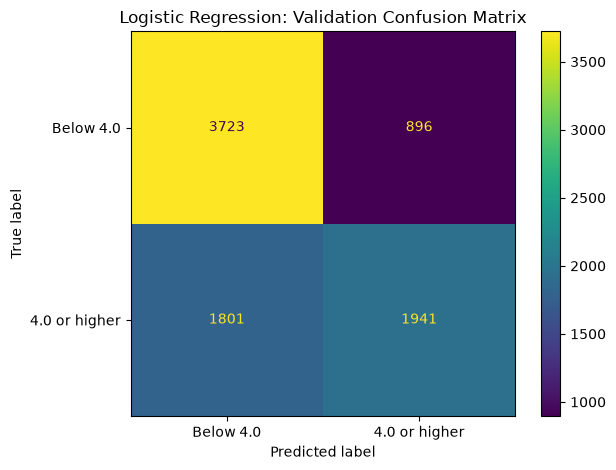

In [10]:
#confusion matrix and classification report 
y_pred = logit_model.predict(X_valid)
y_prob = logit_model.predict_proba(X_valid)[:, 1]

print(classification_report(
    y_valid, y_pred,
    target_names=["Below 4.0 stars", "4.0+ stars"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_valid, y_pred,
    display_labels=["Below 4.0", "4.0 or higher"],
    values_format="d"
)
plt.title("Logistic Regression: Validation Confusion Matrix")
plt.tight_layout()
plt.show()

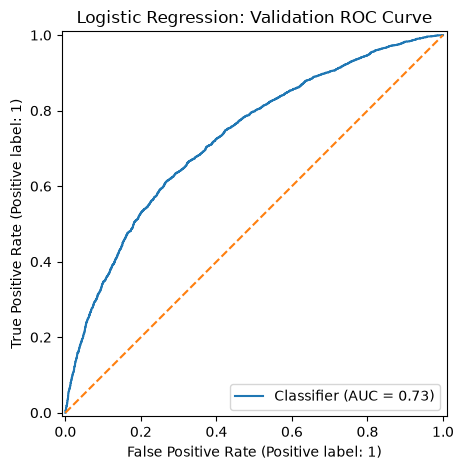

Validation ROC-AUC: 0.727


In [11]:
#ROC curve 
RocCurveDisplay.from_predictions(y_valid, y_prob)
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("Logistic Regression: Validation ROC Curve")
plt.tight_layout()
plt.show()

print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_prob):.3f}")

In [ ]:
#model coefficients 
fitted_preprocessor = logit_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = logit_model.named_steps["logistic_regression"].coef_[0]

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients)
})

print("Largest positive coefficients:")
display(coef_table.sort_values("coefficient", ascending=False).head(15).round(3))

print("Largest negative coefficients:")
display(coef_table.sort_values("coefficient").head(15).round(3))

Largest positive coefficients:


,feature,coefficient,odds_ratio
38,categorical__noise_level_average,0.486,1.626
40,categorical__noise_level_quiet,0.462,1.587
32,categorical__alcohol_beer_and_wine,0.367,1.443
2,numeric__category_count,0.231,1.260
13,categorical__state_LA,0.209,1.233
7,categorical__state_CA,0.176,1.192
5,categorical__state_AB,0.129,1.138
12,categorical__state_IN,0.077,1.081
17,categorical__state_PA,0.076,1.079
25,categorical__takeout_Yes,0.069,1.072


Largest negative coefficients:


,feature,coefficient,odds_ratio
41,categorical__noise_level_very_loud,-0.937,0.392
33,categorical__alcohol_full_bar,-0.549,0.577
4,numeric__weekly_listed_hours,-0.461,0.631
20,categorical__price_range_1.0,-0.319,0.727
3,numeric__listed_days,-0.285,0.752
37,categorical__wifi_paid,-0.285,0.752
24,categorical__takeout_No,-0.273,0.761
6,categorical__state_AZ,-0.242,0.785
39,categorical__noise_level_loud,-0.215,0.807
28,categorical__outdoor_seating_No,-0.206,0.814


count    8361.000
mean        0.447
std         0.181
min         0.023
25%         0.320
50%         0.423
75%         0.559
max         0.981
Name: predicted_probability_high_rating, dtype: float64


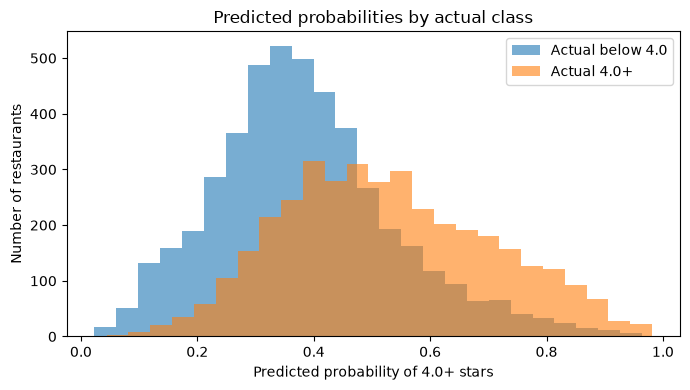

In [ ]:
#checking predicted probabilities 
probability_summary = pd.DataFrame({
    "actual_high_rating": y_valid.to_numpy(),
    "predicted_probability_high_rating": y_prob
})

print(probability_summary["predicted_probability_high_rating"].describe().round(3))

plt.figure(figsize=(7, 4))
plt.hist(y_prob[y_valid.to_numpy() == 0], bins=25, alpha=0.6, label="Actual below 4.0")
plt.hist(y_prob[y_valid.to_numpy() == 1], bins=25, alpha=0.6, label="Actual 4.0+")
plt.xlabel("Predicted probability of 4.0+ stars")
plt.ylabel("Number of restaurants")
plt.title("Predicted probabilities by actual class")
plt.legend()
plt.tight_layout()
plt.show()